In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## radar-chart

**Figure 3: Accuracy (%) of three 8–9B models across six benchmarks.** Numbers give Ours-8B's accuracy on each benchmark. Ours-8B has the most balanced profile, with its largest gains on GSM8K (79.6 vs. 75.1 for Llama-3-8B) and MATH (41.5 vs. 36.6 for Gemma-2-9B).

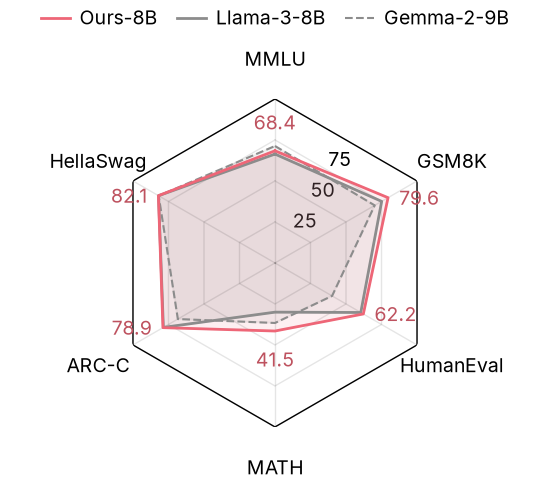

In [2]:
with open("../data/radar-chart.json") as f:
    data = json.load(f)
names = data["benchmarks"]
scores = data["scores"]
n = len(names)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
loop = np.r_[angles, angles[:1]]
rings = [25, 50, 75, 100]

fig, ax = plt.subplots(figsize=(2.75, 2.75), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.grid(False)
ax.spines["polar"].set_visible(False)
for r in rings:
    ax.plot(loop, [r] * (n + 1), color=colors["ink"], alpha=0.1, linewidth=0.5)
for a in angles:
    ax.plot([a, a], [0, rings[-1]], color=colors["ink"], alpha=0.1, linewidth=0.5)
ax.plot(loop, [rings[-1]] * (n + 1), color=colors["ink"], linewidth=0.5)
ax.set_ylim(0, rings[-1])

handles = {}
for model, linestyle in [("Llama-3-8B", "-"), ("Gemma-2-9B", "--")]:
    values = scores[model]
    (handles[model],) = ax.plot(loop, np.r_[values, values[:1]], color=colors["neutral"], linestyle=linestyle,
                                linewidth=paper.dashed_width if linestyle != "-" else None, label=model)
    ax.fill(angles, values, color=colors["neutral"], alpha=0.1)
values = scores["Ours-8B"]
(handles["Ours-8B"],) = ax.plot(loop, np.r_[values, values[:1]], color=colors["ours"], label="Ours-8B")
ax.fill(angles, values, color=colors["ours"], alpha=0.1)
for angle, v in zip(angles, values):
    # sideways on the diagonal spokes, so the label clears the benchmark name beyond the vertex
    side = np.sign(np.sin(angle)) if abs(np.cos(angle)) < 0.9 else 0
    ax.annotate(f"{v:#.3g}", (angle, v), xytext=(4 * side, 0 if side else 6 * np.sign(np.cos(angle))),
                textcoords="offset points", ha={1: "left", -1: "right", 0: "center"}[side],
                va="center" if side else "bottom" if np.cos(angle) > 0 else "top", color=darken(colors["ours"]))

ax.set_xticks(angles, labels=names)
ax.tick_params(axis="x", pad=6)
ax.set_yticks([r * np.cos(np.pi / n) for r in rings[:-1]], labels=[str(r) for r in rings[:-1]])
ax.set_rlabel_position(180 / n)

order = ["Ours-8B", "Llama-3-8B", "Gemma-2-9B"]
fig.legend([handles[m] for m in order], order, loc="outside upper center", ncol=3, frameon=False, borderaxespad=0)

fit_height(fig, ax)
fig.savefig("../outputs/radar-chart.pdf")
fig.savefig("../outputs/radar-chart.png")
plt.show()